# 13 · Agent reliability and experimental design

**Question.** Does adaptive tool use improve outcomes enough to justify its additional complexity?

[Download the executed notebook](https://chikuang.github.io/teaching/genai/notebooks/13-agent-reliability.ipynb)

**Python support:** Read [A.9: JSON and validation](https://chikuang.github.io/teaching/genai/appendices/a-python-pytorch.html#a-9-structured-requests-validation-and-errors) and [A.11: local modules and kernels](https://chikuang.github.io/teaching/genai/appendices/a-python-pytorch.html#a-11-files-local-modules-and-a-fresh-notebook-kernel) before the implementation. Use **Show all code** while working.


A successful demonstration does not measure reliability. We need repeated tasks, failures with known causes, and a comparison that accounts for additional calls. This chapter constructs a controlled simulator: a cached answer, a one-pass tool workflow, and a bounded retry policy solve the same mean-estimation requests. These are programmed policies, not measured LLM agents. Their role is to teach experimental design before introducing an expensive or opaque policy.

**Prerequisites:** Chapters 11–12. **Outcomes:** distinguish trajectories from tasks; classify failure modes; inject reproducible failures; compare paired outcomes with clustered uncertainty; measure the cost of recovery.

## Pipeline and framework

![Run paired policies on the same held-out tasks and repeated failure scenarios, log full trajectories, aggregate by task, bootstrap task clusters and inspect ablations. Remember: pair the tasks; resample task clusters, not individual calls.](https://chikuang.github.io/teaching/genai/_static/diagrams/13-reliability.png)

An agent evaluation needs a **task-level experimental design** and a **trajectory-level trace**. The trace explains a result; the task is often the unit used for population-level uncertainty. A retry can create more calls without creating more independent tasks.

| Stage | Artifact | Why it is needed |
|:--|:--|:--|
| Specify tasks and failures | Task IDs, repetitions, and a reproducible failure process | Different policies face comparable difficulty. |
| Execute paired policies | One trace per policy, task, and repetition | Compare like with like and retain errors and stop reasons. |
| Aggregate and resample | Task-level paired differences | Keep within-task dependence when estimating uncertainty. |
| Diagnose interventions | Success, cost, failure labels, and ablation contrasts | Find whether gains came from retries, memory, or another component. |

In this chapter the tool outcomes and policies are programmed experiments. They demonstrate how to measure reliability, not a measured claim about an external LLM. When moving to a stochastic model, add model/version and decoding settings to the trace and repeat generations under the same task design. If tasks share a source document or user, consider that larger cluster when defining the sampling unit.

## 13.1 · Define success and record the whole trajectory

A task requests the mean of a current dataset. Success requires a numeric answer within a fixed tolerance of the true current mean. A cached answer may be stale. A tool can time out or return malformed data. Abstention, incorrect answers, invalid tool payloads, and exhaustion of the call budget are different outcomes and remain separate in the log.

For task $i$ and replicate $r$, let $S_{ir}$ be success and $C_{ir}$ the number of tool calls. We report mean success, mean calls, and a declared utility $S_{ir}-\lambda C_{ir}$. The value of $\lambda$ is a decision preference, not a quantity the experiment magically identifies.

### Specify the task population and policy contrast

For policy $\pi$, define $U_{ir}^{\pi}=S_{ir}^{\pi}-\lambda C_{ir}^{\pi}$ and

$$
V(\pi)=\mathbb E_{Q}\mathbb E_{\xi\mid Q}
[S^{\pi}(Q,\xi)-\lambda C^{\pi}(Q,\xi)].
$$

Here $Q$ is a sampled task and $\xi$ denotes environment and policy randomness. Using the policy value in Equation [(13.1)](https://chikuang.github.io/teaching/genai/chapters/13-agent-reliability.html#equation-eq-policy-value), the comparison target is $\Delta=V(\pi_B)-V(\pi_A)$. With $n$ tasks and $m$ repetitions each,

$$
D_{ir}=U_{ir}^{B}-U_{ir}^{A},\qquad
\overline D_i=\frac1m\sum_{r=1}^m D_{ir},\qquad
\widehat\Delta=\frac1n\sum_{i=1}^n\overline D_i.
$$

Equation [(13.2)](https://chikuang.github.io/teaching/genai/chapters/13-agent-reliability.html#equation-eq-task-contrast) gives every task equal weight. With unequal repetition counts $m_i$, averaging all trajectories together would instead weight tasks by $m_i$. The success comparison in Section 13.4 is this estimator with $\lambda=0$; Section 13.5 reports utility with $\lambda=0.03$.

## 13.2 · Construct tasks and repeatable tool failures

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

rng = np.random.default_rng(13)
n_tasks, repeats = 80, 5
old_data = rng.normal(size=(n_tasks, 20))
changed = rng.random(n_tasks) < 0.4
current_data = old_data + changed[:, None]*0.5
cached_means = old_data.mean(1)
truth = current_data.mean(1)
failure_probability = rng.uniform(0.1, 0.45, size=n_tasks)

def lookup(task, replicate, attempt):
    # Same task/replicate/attempt produces the same observation for every policy.
    local = np.random.default_rng(130000 + 1000*task + 10*replicate + attempt)
    u = local.random()
    if u < 0.03:
        return {'status': 'malformed', 'values': ['not a number']}
    if u < 0.03 + failure_probability[task]:
        return {'status': 'timeout'}
    return {'status': 'ok', 'values': current_data[task].tolist()}

print('Tasks with stale cached answers:', int(changed.sum()))
print('Range of timeout probabilities:', failure_probability.min().round(2),
      failure_probability.max().round(2))

Tasks with stale cached answers: 31
Range of timeout probabilities: 0.11 0.45


Common random streams make a policy's first call encounter the same failure as another policy's first call. Later attempts have their own observations. This creates a paired experiment rather than confounding the comparison with unrelated random failures. All failure rates and stale-data shifts are chosen for illustration.

| Attempt limit | Cache off | Cache on |
|:--|:--|:--|
| 1 | One pass `(1, False)` | One pass plus cache `(1, True)` |
| 3 | Retry up to 3 `(3, False)` | Retry plus cache `(3, True)` |

`Cache only = (0, True)` is outside this table. Here "no retry" means one initial attempt, not zero attempts. A malformed payload ends the run without fallback; cache is used only after the allowed timeout attempts are exhausted. This rule is fixed in all four cells.

## 13.3 · Compare policy interventions

The retry policy retries timeouts up to a call budget. It stops on a malformed payload because a data-contract violation is not assumed transient. The optional cache fallback is an explicit ablation: it may answer more often while using stale information.

In [2]:
def run_policy(task, replicate, budget, use_cache=False):
    trace = []
    for attempt in range(budget):
        observation = lookup(task, replicate, attempt)
        trace.append(observation['status'])
        if observation['status'] == 'ok':
            value = float(np.mean(observation['values']))
            return {'value': value, 'status': 'answered', 'calls': len(trace), 'trace': trace}
        if observation['status'] == 'malformed':
            return {'value': None, 'status': 'invalid_payload', 'calls': len(trace), 'trace': trace}
    if use_cache:
        return {'value': float(cached_means[task]), 'status': 'cached',
                'calls': len(trace), 'trace': trace}
    return {'value': None, 'status': 'budget_exhausted', 'calls': len(trace), 'trace': trace}

configurations = {'Cache only': (0, True), 'One pass': (1, False),
                  'One pass plus cache': (1, True),
                  'Retry up to 3': (3, False), 'Retry plus cache': (3, True)}
results = {}
for name, (budget, fallback) in configurations.items():
    rows = []
    for task in range(n_tasks):
        for replicate in range(repeats):
            result = run_policy(task, replicate, budget, fallback)
            result.update(task=task, replicate=replicate)
            result['success'] = (result['value'] is not None
                                 and abs(result['value']-truth[task]) < 1e-8)
            rows.append(result)
    results[name] = rows
    print(name, 'success', round(np.mean([r['success'] for r in rows]), 3),
          'calls', round(np.mean([r['calls'] for r in rows]), 3),
          'outcomes', dict(Counter(r['status'] for r in rows)))

Cache only success 0.612 calls 0.0 outcomes {'cached': 400}
One pass success 0.692 calls 1.0 outcomes {'answered': 277, 'budget_exhausted': 111, 'invalid_payload': 12}
One pass plus cache success 0.85 calls 1.0 outcomes {'answered': 277, 'cached': 111, 'invalid_payload': 12}
Retry up to 3 success 0.93 calls 1.39 outcomes {'answered': 372, 'budget_exhausted': 14, 'invalid_payload': 14}
Retry plus cache success 0.952 calls 1.39 outcomes {'answered': 372, 'cached': 14, 'invalid_payload': 14}


This comparison does not show that a language model is needed. The adaptive behavior is a short programmed policy. It tests the benefit of retries and the risk of stale fallback under specified failure mechanisms. An actual LLM comparison would replace the policy while retaining the task set, dispatcher, scoring rule, and trace accounting.

> **Example 13.1 · Retries trade additional calls for recovery**
>
> **Setup.** Suppose every attempt independently fails with probability $0.2$, all failures are transient, and a policy allows at most three attempts, stopping immediately on success.
>
> **Work it through.** Success probability is $1-0.2^3=0.992$, versus $0.8$ with one attempt. Expected calls are $1+0.2+0.2^2=1.24$, because attempts 2 and 3 occur only after preceding failures. With $\lambda=0.1$, Equation [(13.1)](https://chikuang.github.io/teaching/genai/chapters/13-agent-reliability.html#equation-eq-policy-value) gives retry utility $0.992-0.1(1.24)=0.868$, versus $0.8-0.1=0.7$ for one attempt.
>
> **What this shows.** Report realized expected cost, not just the three-call ceiling. The calculation depends on independent transient failures. If an invalid dataset name makes every attempt fail, retrying the same request adds cost without recovery; classifying the error changes the appropriate policy.

## 13.4 · Resample tasks, keeping repetitions together

Five repetitions of one task share its data, truth, and failure rate. Resampling all 400 trajectories independently would ignore that clustering. We first average the paired success difference within each task and then bootstrap task means.

Retry minus one-pass success: 0.238
Task-cluster bootstrap interval: [0.195 0.28 ]


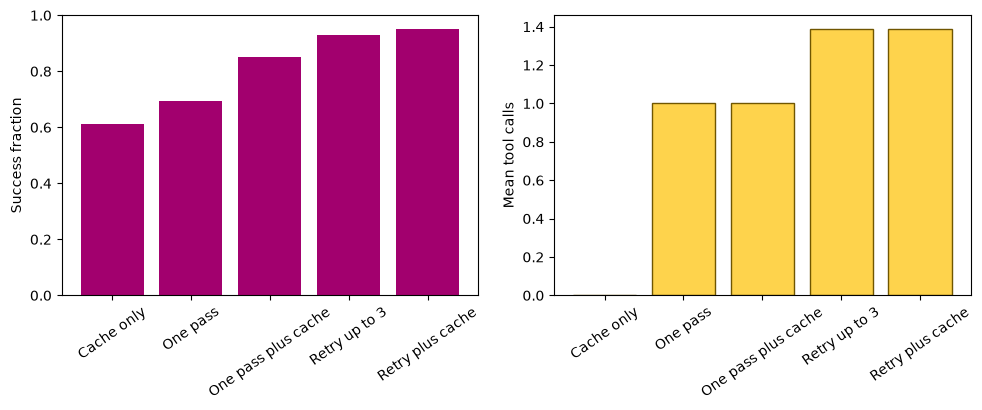

In [3]:
def success_matrix(name):
    return np.array([r['success'] for r in results[name]], dtype=float).reshape(n_tasks, repeats)

paired_by_task = (success_matrix('Retry up to 3')-success_matrix('One pass')).mean(1)
ids = rng.integers(n_tasks, size=(3000, n_tasks))
bootstrap = paired_by_task[ids].mean(1)
print('Retry minus one-pass success:', round(paired_by_task.mean(), 3))
print('Task-cluster bootstrap interval:', np.quantile(bootstrap, [0.025, 0.975]).round(3))

names = list(configurations)
success = [np.mean([r['success'] for r in results[name]]) for name in names]
calls = [np.mean([r['calls'] for r in results[name]]) for name in names]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].bar(names, success, color='#a2006e')
axes[1].bar(names, calls, color='#fed34c', edgecolor='#705600')
axes[0].set(ylabel='Success fraction', ylim=(0, 1))
axes[1].set(ylabel='Mean tool calls')
for ax in axes:
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()

The interval describes the chosen simulator and sampled task distribution. It does not include uncertainty about whether that simulator resembles production. When tasks are sampled by document or user, move the resampling unit to that higher level.

### More repetitions and more tasks reduce different uncertainty

Suppose tasks are iid and repetitions are independent conditional on their task, while A/B outcomes remain paired within each repetition. Write $\delta(Q)=\mathbb E[D_{ir}\mid Q]$ and $\sigma^2(Q)=\operatorname{Var}(D_{ir}\mid Q)$. The law of total variance gives

$$
\operatorname{Var}(\widehat\Delta)=
\frac{\operatorname{Var}_Q\{\delta(Q)\}}{n}
+\frac{\mathbb E_Q\{\sigma^2(Q)\}}{nm}.
$$

In Equation [(13.3)](https://chikuang.github.io/teaching/genai/chapters/13-agent-reliability.html#equation-eq-task-variance), increasing repetitions $m$ reduces the second term, but leaves the between-task term unchanged. More independent tasks $n$ reduce both. Shared failure conditions across repetitions require additional covariance terms; the displayed simplification would no longer hold.

The implemented cluster bootstrap draws $I_1^{(b)},\ldots,I_n^{(b)}$ independently and uniformly from $\{1,\ldots,n\}$ and forms

$$
\widehat\Delta^{*(b)}=\frac1n\sum_{j=1}^n\overline D_{I_j^{(b)}}.
$$

Taking the 0.025 and 0.975 empirical quantiles of these values gives the displayed approximate interval. Equation [(13.4)](https://chikuang.github.io/teaching/genai/chapters/13-agent-reliability.html#equation-eq-cluster-bootstrap) is implemented by `paired_by_task`, which contains the task means from Equation [(13.2)](https://chikuang.github.io/teaching/genai/chapters/13-agent-reliability.html#equation-eq-task-contrast), and `ids`, which selects whole task contributions. Resampling individual calls would change the experimental unit and does not implement this procedure.

> **Example 13.2 · Averaging trajectories can change the target**
>
> **Setup.** Two sampled tasks have observed average paired improvements $0.4$ and $0.0$. The first task was repeated ten times and the second only twice.
>
> **Work it through.** Equal task weighting in Equation [(13.2)](https://chikuang.github.io/teaching/genai/chapters/13-agent-reliability.html#equation-eq-task-contrast) gives $(0.4+0)/2=0.2$. Pooling all twelve trajectories instead gives $[10(0.4)+2(0)]/12\approx0.3333$. For the task-level bootstrap in Equation [(13.4)](https://chikuang.github.io/teaching/genai/chapters/13-agent-reliability.html#equation-eq-cluster-bootstrap), the resampling units are the two complete task contributions, not the twelve individual outcomes.
>
> **What this shows.** A task can receive more influence merely because it was run more often. Choose the population target and weighting before inspecting results. Extra repetitions refine behavior on an existing task; they do not create more independent tasks. Two task clusters illustrate the bookkeeping but provide little information about performance across a broader task population.

## 13.5 · Inspect cost and failure examples

In [4]:
cost_per_call = 0.03
for name, rows in results.items():
    utility = np.mean([float(r['success'])-cost_per_call*r['calls'] for r in rows])
    answered = [r for r in rows if r['value'] is not None]
    wrong_answer_rate = np.mean([not r['success'] for r in answered]) if answered else np.nan
    print(name, 'utility', round(utility, 3),
          'error among answered', round(wrong_answer_rate, 3))

example = next(r for r in results['Retry up to 3'] if len(r['trace']) > 1)
print('Recovery trace:', example)

Cache only utility 0.612 error among answered 0.388
One pass utility 0.662 error among answered 0.0
One pass plus cache utility 0.82 error among answered 0.124
Retry up to 3 utility 0.888 error among answered 0.0
Retry plus cache utility 0.911 error among answered 0.013
Recovery trace: {'value': 0.8543511034891461, 'status': 'answered', 'calls': 2, 'trace': ['timeout', 'ok'], 'task': 1, 'replicate': 2, 'success': np.True_}


These costs are illustrative units per call, not measured currency or wall-clock latency. A deployed experiment should log actual tokens, service charges, elapsed time, retries, and model/tool versions. Do not erase failed trajectories before calculating cost.

A useful failure taxonomy distinguishes task interpretation, invalid action proposals, tool availability, invalid returned data, incorrect calculation, unsupported final answer, and budget exhaustion. A timeout followed by successful recovery is a successful trajectory with an observed intermediate failure, not a run that “never failed.”

## 13.6 · Factorial comparisons and adaptive evaluation

To test memory, vary only the memory feature while holding the other components fixed. To test retries, hold the policy and tool contracts fixed while changing the retry rule. For two factors, evaluate all four combinations and inspect interactions: memory could help after a retrieval failure while harmfully overriding fresh evidence when retrieval succeeds.

For two binary interventions A and B, let $\mu_{ab}$ be expected utility with settings $(a,b)\in\{0,1\}^2$. The interaction contrast is

$$
\Delta_{AB}=(\mu_{11}-\mu_{01})-(\mu_{10}-\mu_{00}).
$$

It asks whether the effect of A changes when B is enabled. Estimate all four conditions on the same tasks and resample the paired task-level contrasts. A positive interaction is scale-dependent and does not establish that either factor improves every task. The experiment now includes all four one/three-call by cache-off/on conditions. The zero-call Cache only condition is an additional baseline and never enters the factorial contrast. The practice below computes paired task contrasts for success and calls.

Do not repeatedly inspect test outcomes, change the policy, and continue calling the same set “held out.” Use a development suite for repairs and a locked evaluation suite for final reporting. Record the number of policy variants considered, since selection among many noisy estimates creates optimism.

Prompt injection tests should include untrusted documents and tool messages that request unauthorized behavior. Score whether the execution boundary rejects invalid actions, not merely whether the final response sounds cautious. The harmless adversarial-note experiment in Chapter 12 is one deterministic unit test, not a comprehensive security evaluation.


### Coding and experiment practice · Complete the factorial contrast

**1. Predict before running.** Why is zero-call Cache only not the cache-enabled cell of a one-call versus three-call experiment?

**2. Implement and check.** Use the four explicitly named one/three-call × cache-off/on conditions. Keep the zero-call cache baseline outside the factorial contrast. Calculate success and call interactions within each task before resampling tasks. Try your own implementation before expanding the reference code below. Replace the reference function body with your version and rerun the acceptance checks in a fresh kernel.

In [5]:
def interaction(one_no_cache, three_no_cache, one_cache, three_cache):
    return three_cache - three_no_cache - one_cache + one_no_cache

assert np.isclose(interaction(0.4, 0.6, 0.5, 0.9), 0.2)
factor_names = ['One pass', 'Retry up to 3', 'One pass plus cache', 'Retry plus cache']
for metric in ['success', 'calls']:
    by_task = []
    for name in factor_names:
        matrix = np.array([row[metric] for row in results[name]], dtype=float).reshape(n_tasks, repeats)
        by_task.append(matrix.mean(axis=1))
        print(metric, name, round(float(matrix.mean()), 4))
    task_contrasts = interaction(*by_task)
    task_ids = np.random.default_rng(1313).integers(n_tasks, size=(2000, n_tasks))
    uncertainty = task_contrasts[task_ids].mean(axis=1)
    print(metric, 'interaction:', round(float(task_contrasts.mean()), 4),
          'task-bootstrap interval:', np.quantile(uncertainty, [0.025, 0.975]).round(4))

success One pass 0.6925
success Retry up to 3 0.93
success One pass plus cache 0.85
success Retry plus cache 0.9525
success interaction: -0.135 task-bootstrap interval: [-0.1775 -0.0975]
calls One pass 1.0
calls Retry up to 3 1.39
calls One pass plus cache 1.0
calls Retry plus cache 1.39
calls interaction: 0.0 task-bootstrap interval: [0. 0.]


Each row of the reshaped matrix is one task and each column one repeated trajectory. Compute the paired contrast before sampling rows. The resulting intervals concern this simulator and task sampling scheme; they do not include uncertainty about whether the simulator resembles an application.

**3. Extend one factor.** Change stale-cache prevalence on a fresh development simulation while holding all four intervention settings fixed. Report both success and cost interactions. A positive success interaction need not imply a positive utility interaction.

**Submission and rubric.** Submit the function and its checks, the requested comparison table, and three sentences naming the target, interpreting the result, and limiting the claim. Passing a deterministic fixture verifies the stated calculation; a favorable stochastic result is not required. Retain unexpected results and diagnose them rather than changing seeds until a preferred ranking appears.


### Continue with the implemented system

The controlled reliability experiment isolates mechanisms. [Appendix B](https://chikuang.github.io/teaching/genai/appendices/b-real-llm-systems.html) adds actual LLM failures and call counts. Its observed failures motivate hypotheses, but its tiny task set and single greedy run cannot estimate general agent reliability. Use the factorial and task-sampling design here when expanding that experiment.

## 13.7 · Exercises

1. **Retry probability:** if independent attempts fail with a fixed probability $p$, what is success by three attempts?
2. **Persistent failure:** why can retries fail to help?
3. **Experimental unit:** why bootstrap 80 tasks rather than 400 trajectories?
4. **Cache fallback:** can answering more questions reduce reliability?
5. **Budget fairness:** are two policies equivalent because both have a three-call ceiling?
6. **Multiple agents:** what baseline should precede adding more agents?


<details><summary>Worked solutions — attempt the questions first</summary>

**1.** $1-p^3$. With task-specific failure rates, average $1-p_i^3$ across tasks; substituting the average failure rate generally gives a different result.

**2.** an invalid credential, missing dataset, or malformed contract can persist across attempts. The independent transient-failure model then does not apply.

**3.** repeated trajectories share task characteristics. Task resampling retains that dependence and targets variation across the sampled task population.

**4.** yes. A stale cache may convert honest abstentions into incorrect answers. Report coverage and error among answered cases together.

**5.** no. Their actual call distributions can differ. Report both the permitted budget and realized costs, and compare utility under a declared cost model.

**6.** a strong single-policy workflow with the same evidence and comparable total budget. Multiple samples, added tools, or extra tokens can explain gains without any benefit from agent-to-agent communication.

</details>

## 13.8 · Transition to a complete project

Use the evaluation principles from [Chapter 11](https://chikuang.github.io/teaching/genai/chapters/11-evaluation-uncertainty.html) with the execution boundary from [Chapter 12](https://chikuang.github.io/teaching/genai/chapters/12-agents.html). [Chapter 14](https://chikuang.github.io/teaching/genai/chapters/14-capstone.html) combines these ideas into a fully runnable statistical simulation assistant and a reproducible project report.